# Matching English and Chinese sermons

My church's app has 91 podcast episodes. Many of them come in two versions, one English and one Chinese, covering the same material. The app knows which folder each episode is in, but nothing says which Chinese episode goes with which English one.

**Question:** if I turn the audio into text, can a model that reads both languages figure out the pairs on its own, without translating anything?

Steps:
1. Transcribe all 29 hours of audio with Whisper (done in `src/transcribe.py`).
2. Clean the transcripts.
3. Turn each episode into a vector with three multilingual embedding models and see how often each one ranks the right Chinese episode first.
4. Look at where it fails, what each series is about, and whether search works across languages.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

from corpus import load_corpus, load_pairs, chunk_segments
from matching import MODELS, embed_corpus, episode_vectors, center_by_language, evaluate, summarize, random_baseline, search
from keywords import top_terms_by_series

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"]
FIGURES = "../figures"

## 1. The data

Each row is one episode. `length` is words for English and characters for Chinese, since Chinese doesn't put spaces between words.

In [2]:
corpus = load_corpus()
pairs = load_pairs()

summary = corpus.groupby("language").agg(
    episodes=("id", "count"),
    hours=("duration_min", lambda m: m.sum() / 60),
    avg_minutes=("duration_min", "mean"),
    avg_length=("length", "mean"),
    segments_removed=("segments_removed", "sum"),
).round(1)
summary

,episodes,hours,avg_minutes,avg_length,segments_removed
language,,,,,
en,37,10.8,17.4,2252.2,789
zh,54,18.4,20.5,3765.1,895


### Cleaning

Whisper is very accurate on speech, but it makes things up during music and silence. Two patterns showed up when I read through the raw transcripts:

- **Phrases from its training data**, like "Thank you." at the start of an episode or "请不吝点赞 订阅 转发 打赏支持明镜与点点栏目" (a YouTube channel's "like and subscribe" line) during the closing music. It even invented a song credit for a famous Taiwanese songwriter.
- **Loops**, where it repeats one short phrase dozens of times, like "No." 38 times in a row at the end of one episode.

`clean_segments` in `src/corpus.py` drops known filler, segments containing song-credit markers, and any segment identical to the one before it. The table above shows how many segments that removed.

In [3]:
corpus.sort_values("segments_removed", ascending=False)[["id", "title", "language", "segments_removed"]].head(5)

,id,title,language,segments_removed
16,p007,05 第五日 憑信心到祂面前,zh,140
7,p057,07 As Your Wisdom,en,100
41,p036,創世記 00,zh,80
18,p009,07 成为你的智慧,zh,76
12,p003,01 凡來到祂面前的人,zh,67


### How fast do the speakers talk?

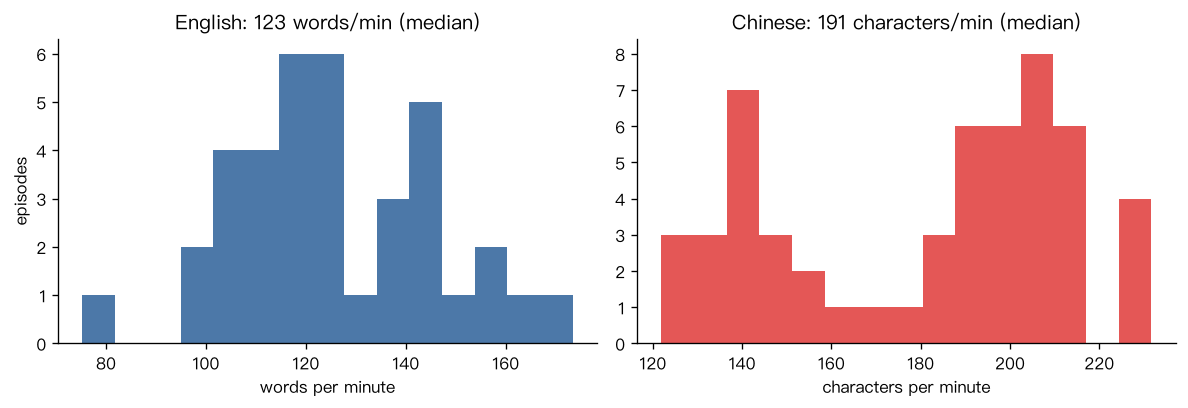

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (lang, unit) in zip(axes, [("en", "words"), ("zh", "characters")]):
    rates = corpus.loc[corpus["language"] == lang, "rate_per_min"]
    ax.hist(rates, bins=15, color="#4C78A8" if lang == "en" else "#E45756")
    ax.set_title(f"{'English' if lang == 'en' else 'Chinese'}: {rates.median():.0f} {unit}/min (median)")
    ax.set_xlabel(f"{unit} per minute")
axes[0].set_ylabel("episodes")
plt.tight_layout()
plt.savefig(f"{FIGURES}/speaking_rate.png", bbox_inches="tight")

The Chinese histogram has two humps. Splitting by series shows why:

In [5]:
corpus.pivot_table(index="series", columns="language", values="rate_per_min", aggfunc="median").round(0)

language,en,zh
series,,
Abide in Christ,118.0,138.0
Boys and Girls,135.0,NaN
Exodus,132.0,193.0
Genesis,NaN,215.0
John,NaN,201.0
Leviticus,129.0,199.0
Morning Watch Guide,106.0,133.0
Numbers,137.0,187.0
The Octave of Redemption,151.0,198.0


The slow group is the devotional material (*Abide in Christ*, *Morning Watch Guide*), which is read aloud carefully. The fast group is Bible study teaching (*Exodus*, *Genesis*, *The Octave of Redemption*), which is closer to normal conversation speed. English shows the same split, just less dramatically.

## 2. Can a model match the pairs?

I labeled the answer key by hand in `pairs.csv`: 35 English episodes, each with its Chinese counterpart. *The Octave of Redemption* is split differently in Chinese (6 English chapters vs. 13 Chinese parts), so some English episodes have two to four correct Chinese answers. Any of them counts.

**Method.** Each transcript gets cut into passages of about 120 English words or 250 Chinese characters. Each passage becomes a vector, and the episode's vector is the average of its passages. Then for every English episode I rank all 56 Chinese episodes by cosine similarity and check where the right one lands.

**Metrics.**
- Top-1 accuracy: how often the right episode is ranked first.
- Top-3 accuracy: how often it's in the top three.
- Mean reciprocal rank (MRR): average of 1/rank, so first place scores 1, second 0.5, third 0.33.

For comparison, random guessing is estimated by shuffling the ranking 2,000 times.

In [6]:
zh_ids = corpus.loc[corpus["language"] == "zh", "id"].tolist()
results, embedded_by_model, ranks_by_model = {}, {}, {}

for name, model_id in MODELS.items():
    model = SentenceTransformer(model_id)
    embedded = embed_corpus(corpus, model)
    ranks = evaluate(pairs, episode_vectors(embedded), zh_ids)
    results[name] = summarize(ranks)
    embedded_by_model[name] = (model, embedded)
    ranks_by_model[name] = ranks

results["Random guessing"] = random_baseline(pairs, zh_ids)
scores = pd.DataFrame(results).T.round(3)
scores

,top-1 accuracy,top-3 accuracy,mean reciprocal rank
MiniLM (multilingual),0.943,0.943,0.952
LaBSE,0.914,1.000,0.948
BGE-M3,0.971,1.000,0.986
Random guessing,0.021,0.065,0.093


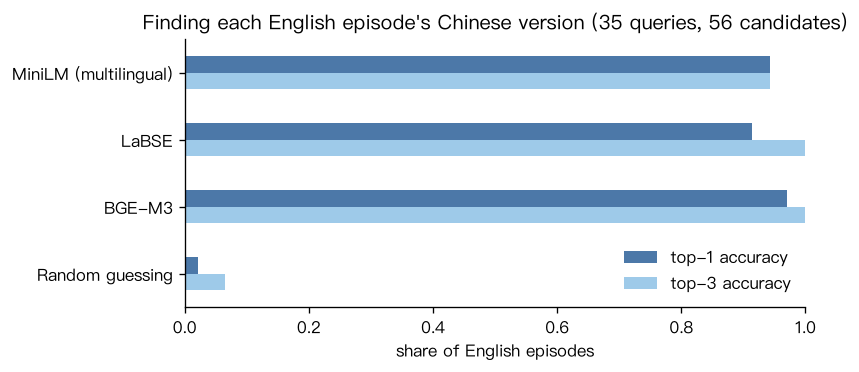

In [7]:
ax = scores[["top-1 accuracy", "top-3 accuracy"]].plot.barh(figsize=(7, 3.2), color=["#4C78A8", "#9ecae9"])
ax.set_xlim(0, 1)
ax.set_xlabel("share of English episodes")
ax.invert_yaxis()
ax.legend(loc="lower right", frameon=False)
plt.title("Finding each English episode's Chinese version (35 queries, 56 candidates)")
plt.tight_layout()
plt.savefig(f"{FIGURES}/matching_accuracy.png", bbox_inches="tight")

### Accuracy by series

In [8]:
by_series = pd.DataFrame({
    name: ranks.groupby("series")["rank"].apply(lambda r: (r == 1).mean())
    for name, ranks in ranks_by_model.items()
})
by_series["episodes"] = pairs.groupby("series").size()
by_series.round(2)

,MiniLM (multilingual),LaBSE,BGE-M3,episodes
series,,,,
Abide in Christ,1.00,1.0,0.91,11
Exodus,1.00,1.0,1.00,8
Leviticus,1.00,1.0,1.00,1
Morning Watch Guide,1.00,1.0,1.00,7
Numbers,1.00,1.0,1.00,1
The Octave of Redemption,0.67,0.5,1.00,6
What is Man,1.00,1.0,1.00,1


### Does removing the "language direction" help?

The map in section 4 shows that English and Chinese episodes sit in two separate regions, even though the model is supposed to be language-neutral. A common fix is to subtract each language's average vector so only the meaning is left. Here's the same test with that adjustment.

In [9]:
languages = corpus.set_index("id")["language"].to_dict()
centered_results = {}
for name, (model, embedded) in embedded_by_model.items():
    centered = center_by_language(episode_vectors(embedded), languages)
    centered_results[name] = summarize(evaluate(pairs, centered, zh_ids))

pd.concat({"original": scores.drop("Random guessing"), "language-centered": pd.DataFrame(centered_results).T.round(3)}, axis=1)

original                                      \
                      top-1 accuracy top-3 accuracy mean reciprocal rank   
MiniLM (multilingual)          0.943          0.943                0.952   
LaBSE                          0.914          1.000                0.948   
BGE-M3                         0.971          1.000                0.986   

                      language-centered                                      
                         top-1 accuracy top-3 accuracy mean reciprocal rank  
MiniLM (multilingual)             0.857          0.971                0.913  
LaBSE                             0.886          1.000                0.933  
BGE-M3                            0.943          1.000                0.971

### Where it goes wrong

The misses for the best model. `top_match` is the Chinese episode it picked instead.

In [10]:
best = scores.drop("Random guessing")["mean reciprocal rank"].idxmax()
titles = corpus.set_index("id")["title"]
misses = ranks_by_model[best].query("rank > 1").copy()
misses["english_title"] = misses["en_id"].map(titles)
misses["picked_instead"] = misses["top_match"].map(titles)
misses["correct"] = misses["en_id"].map(pairs.set_index("en_id")["zh_ids"]).apply(lambda ids: ", ".join(titles[i] for i in ids))
print("Best model:", best)
misses[["series", "english_title", "picked_instead", "correct", "rank"]]

Best model: BGE-M3


,series,english_title,picked_instead,correct,rank
8,Abide in Christ,08 As Your Righteousness,10 成为你的救赎,08 成为你的公义,2


## 3. Do the two versions follow the same order inside an episode?

Matching whole episodes doesn't say whether the Chinese version actually follows the English one line by line, or just covers the same topic. Comparing every English passage against every Chinese passage in one pair shows that. If the two follow the same order, the bright cells form a diagonal.

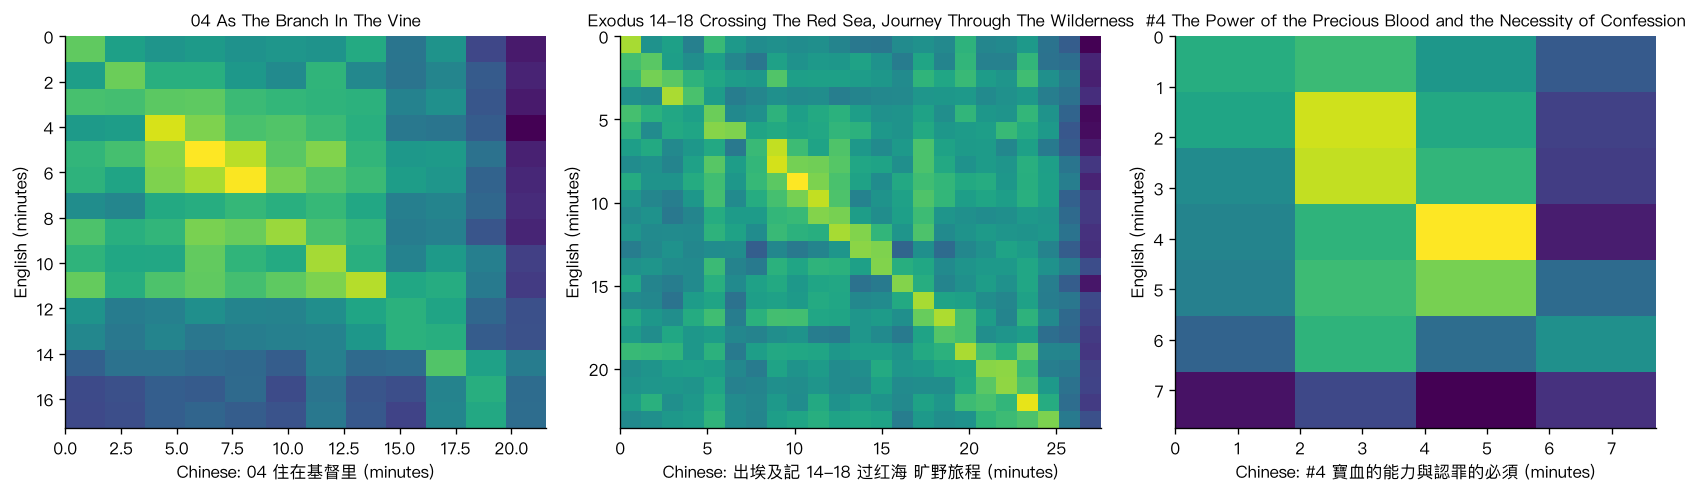

In [11]:
model, embedded = embedded_by_model[best]

def alignment_plot(en_id, zh_id, ax):
    en_vecs, en_passages = embedded[en_id]
    zh_vecs, zh_passages = embedded[zh_id]
    sim = en_vecs @ zh_vecs.T
    ax.imshow(sim, aspect="auto", cmap="viridis", origin="upper",
              extent=[0, zh_passages[-1]["end"] / 60, en_passages[-1]["end"] / 60, 0])
    ax.set_xlabel(f"Chinese: {titles[zh_id]} (minutes)")
    ax.set_ylabel(f"English (minutes)")
    ax.set_title(titles[en_id], fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (en_id, zh_id) in zip(axes, [("p054", "p006"), ("p087", "p080"), ("p026", "p017")]):
    alignment_plot(en_id, zh_id, ax)
plt.tight_layout()
plt.savefig(f"{FIGURES}/passage_alignment.png", bbox_inches="tight")

## 4. A map of every episode

The best model's episode vectors squeezed down to two dimensions with PCA (principal component analysis). Color is the series and the marker shape is the language. If the model really understood both languages the same way, English and Chinese episodes from the same series would land near each other.

The left map shows they don't: the biggest difference PCA finds is the language itself. Removing each language's average vector (right) takes that out, and the pairs move together.

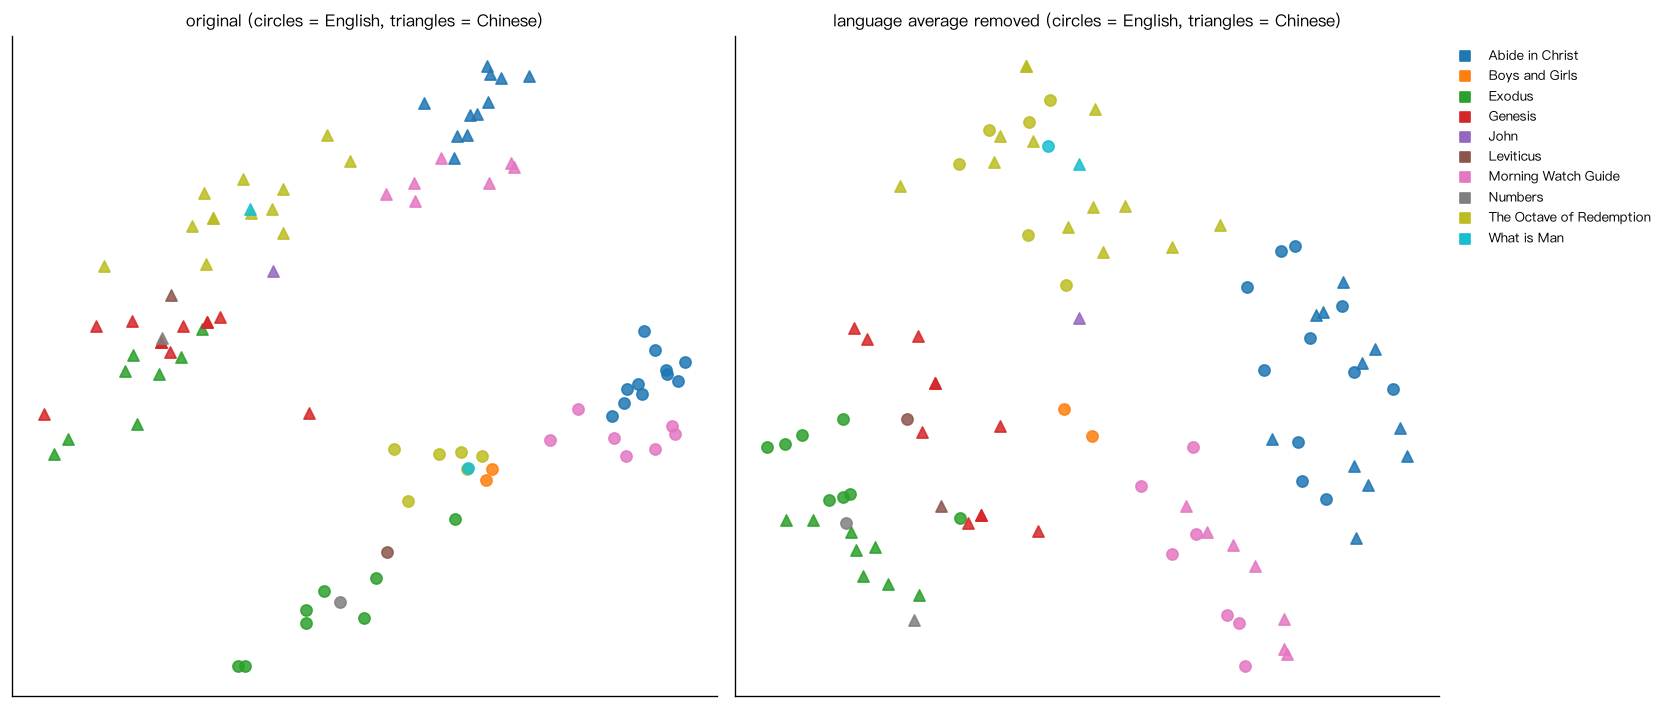

In [12]:
from sklearn.decomposition import PCA

ids = corpus["id"].tolist()
palette = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (label, vectors) in zip(axes, [
    ("original", episode_vectors(embedded)),
    ("language average removed", center_by_language(episode_vectors(embedded), languages)),
]):
    points = PCA(n_components=2, random_state=0).fit_transform(np.stack([vectors[i] for i in ids]))
    frame = corpus[["id", "series", "language"]].assign(x=points[:, 0], y=points[:, 1])
    for k, (series, group) in enumerate(frame.groupby("series")):
        color = palette(k % 10)
        for lang, marker in [("en", "o"), ("zh", "^")]:
            g = group[group["language"] == lang]
            ax.scatter(g["x"], g["y"], color=color, marker=marker, s=45, alpha=0.85)
        if ax is axes[-1]:
            ax.scatter([], [], color=color, marker="s", label=series)  # one legend entry per series
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{label} (circles = English, triangles = Chinese)", fontsize=10)

axes[-1].legend(fontsize=8, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIGURES}/episode_map.png", bbox_inches="tight")

## 5. What makes each series different

TF-IDF scores a word highly when it shows up often in one series but rarely in the others. English uses scikit-learn's built-in stop words. Chinese is split into words with jieba first, with a short custom stop word list.

In [13]:
pd.set_option("display.max_colwidth", 120)
pd.concat([top_terms_by_series(corpus, "en"), top_terms_by_series(corpus, "zh")]).reset_index(drop=True)

,series,language,top_terms
0,Abide in Christ,en,"abide, vine, branch, abiding, righteousness, savior, holy, faith"
1,Boys and Girls,en,"wall, skin, hurt, parts, member, nehemiah, lighting, rush"
2,Exodus,en,"moses, egypt, exodus, law, tabernacle, abraham, pharaoh, covenant"
3,Morning Watch Guide,en,"morning, intercession, spirit, words, heart, holy, obey, fellowship"
4,The Octave of Redemption,en,"cross, spirit, days, holy, ground, faith, son, great"
5,Abide in Christ,zh,"葡萄树, 枝子, 信徒, 智慧, 安息, 时时刻刻, 救赎, 保守"
6,Exodus,zh,"百姓, 埃及, 摩西, 律法, 出埃及记, 世界, 祭司, 会幕"
7,Genesis,zh,"亚伯拉罕, 创世纪, 雅各, 女人, 撒旦, 分开, 应许, 亚伯"
8,Morning Watch Guide,zh,"代导, 赞美, 怀中, 何等, 顺从, 早晨, 喜乐, 陈庚"
9,The Octave of Redemption,zh,"撒旦, 十字架, 世界, 管制, 原则, 立场, 亚当, 属天"


## 6. Searching across languages

Since both languages live in the same vector space, an English question can find Chinese passages directly. This returns the closest Chinese passages and where they start, which is what a search feature in the app would need.

In [14]:
for query in ["the importance of prayer early in the morning", "crossing the Red Sea", "the vine and the branches"]:
    print(f"\n{query}")
    print(search(query, model, embedded, corpus, language="zh", top_k=3).round(3).to_string(index=False))


the importance of prayer early in the morning
 similarity   id  episode  starts_at_sec
      0.680 p022 #1 晨更的重要         131.84
      0.652 p023 #2 如何守晨更         146.58
      0.631 p023 #2 如何守晨更         232.70

crossing the Red Sea
 similarity   id             episode  starts_at_sec
      0.537 p080 出埃及記 14-18 过红海 旷野旅程         263.10
      0.534 p080 出埃及記 14-18 过红海 旷野旅程         546.54
      0.524 p080 出埃及記 14-18 过红海 旷野旅程         679.88

the vine and the branches
 similarity   id  episode  starts_at_sec
      0.525 p006 04 住在基督里         567.36
      0.511 p006 04 住在基督里         472.42
      0.509 p006 04 住在基督里          89.98


## Takeaways

- **It works, and well.** BGE-M3 ranked the right Chinese episode first for 34 of 35 English episodes and had it in the top three every time. Random guessing gets about 2%. No translation step was needed.
- **The one miss makes sense.** "08 As Your Righteousness" was matched to "10 成为你的救赎" (As Your Redemption). Chapters 7 through 10 of *Abide in Christ* all come from the same Bible verse (1 Corinthians 1:30) and follow the same structure, so they really are close. The correct episode came in second.
- **Bigger model, harder cases.** All three models do fine on series where each English episode has exactly one Chinese version. *The Octave of Redemption*, where the Chinese version is split into more and differently sized parts, is where the smaller models slip (50 to 67% top-1) and BGE-M3 still gets all 6.
- **The Chinese versions follow the English ones closely.** The passage-by-passage heatmaps show a clear diagonal for *Exodus*, meaning the Chinese lesson covers the same points in the same order.
- **"Language-neutral" isn't fully neutral.** Every model still puts English and Chinese in separate regions. Removing each language's average fixes the picture, but it made matching slightly worse, probably because every candidate was Chinese anyway, so the shared offset never affected the ranking and removing it only threw away some real signal.
- **Whisper struggles with church vocabulary.** Two of the "distinctive" Chinese words are mistakes: 陈庚 should be 晨更 (morning watch) and 代导 should be 代祷 (intercession). The sounds are right and the characters are wrong, because those words are rare outside of church. Putting a short list of church terms in Whisper's prompt is the obvious next fix.

**Limitations.** 35 test pairs is small, and I made the answer key myself from the titles. I spot-checked transcripts but didn't proofread all 29 hours. Some pairs could be matched partly by topic (any Exodus episode looks like Exodus), which is why I looked at the misses and the per-passage heatmaps instead of trusting the accuracy number alone.

**Next steps.** Add church terms to the Whisper prompt and measure how many errors it fixes. Build an actual "search in either language" feature for the church app, using the passage start times to jump straight to the right point in an episode.